# ESID4HPO — between-disease separation of individuals (Supplementary Figure S4, Table S8)

**Question.** Does the curated vocabulary make the three cohorts more distinguishable from
phenotype alone, without disease annotations and without a ranking algorithm?

Every individual exists in two versions (post-workshop as curated, pre-workshop aged to
v2024-08-13), so the endpoint is the **change in separation**, tested within individuals.

Adapted from Campos et al. 2026 (`Analysing-CVID-HPO/scripts/Figure3_prep.R`): minimal term
sets, pairwise Lin similarity (best-match average), MDS on `1 - sim`, PERMANOVA. Added here:
per-individual silhouette width as the paired primary endpoint, sign-flip permutation across
arms, Resnik as alternative similarity, two IC sources, and a publication-batch check.

| setting | primary | sensitivity |
|---|---|---|
| IC source | intrinsic (graph-based, v2026-06-23) | augmented HPOA (as Figure 3, full corpus, no LOO) |
| term similarity | Lin BMA (symmetric) | Resnik BMA |
| features | observed only, minimal set | — |
| graph | v2026-06-23 for both arms | — |

Outputs land in `_work/intermediate/separation_*.csv`, `_work/tables/tableS8a_separation_cohorts.csv` to `tableS8c_separation_publications.csv` and
`_work/figures/figS4a_separation_mds.*`, `figS4b_separation_similarity.*`.

## 0  Setup (mirrors `esid4hpo_analysis.ipynb`)

In [1]:
import csv, math, os, pathlib, re, itertools
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import hpotk
from google.protobuf.json_format import Parse
from phenopackets.schema.v2.phenopackets_pb2 import Phenopacket
from scipy import stats
from scipy.spatial import ConvexHull
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

FPATH_NB   = pathlib.Path(os.getcwd())
FPATH_SRC  = FPATH_NB.parent
FPATH_COH  = FPATH_SRC / "cohorts"
FPATH_WORK = FPATH_NB / "_work"
FPATH_FIGS = FPATH_WORK / "figures"
FPATH_FIGS.mkdir(parents=True, exist_ok=True)

HPO_OLD_TAG = "v2024-08-13"
HPO_NEW_TAG = "v2026-06-23"
ROOT        = "HP:0000118"           # Phenotypic abnormality
SEED        = 20260813
N_PERM_LABEL = 999                   # PERMANOVA label permutations
N_PERM_FLIP  = 5000                  # pre/post sign-flip permutations
rng = np.random.default_rng(SEED)

In [2]:
@dataclass(frozen=True)
class Cohort:
    name: str
    disease_id: str
    color: str
    pp_subdir: str = "phenopackets"
    def pp_dir(self, root=FPATH_COH):
        return root / self.name / self.pp_subdir

# BIH palette: navy, gold, teal
COHORTS = [
    Cohort("SOCS1", "OMIM:619375", "#003754"),
    Cohort("APDS1", "OMIM:615513", "#C8A870"),
    Cohort("NFKB1", "OMIM:616576", "#4E7E96"),
]
ACTIVE = [c for c in COHORTS if c.pp_dir().is_dir() and any(c.pp_dir().glob("*.json"))]
COLOR  = {c.name: c.color for c in COHORTS}
ORDER  = [c.name for c in ACTIVE]
for c in ACTIVE:
    print(f"{c.name:6s} {len(list(c.pp_dir().glob('*.json'))):3d} phenopackets")


def load_hpo(tag):
    local = FPATH_WORK / "data" / ("old" if tag == HPO_OLD_TAG else "new") / "hp.json"
    if local.exists():
        return hpotk.load_minimal_ontology(str(local))
    return hpotk.configure_ontology_store().load_minimal_hpo(release=tag)

hpo_old = load_hpo(HPO_OLD_TAG)
hpo_new = load_hpo(HPO_NEW_TAG)
print("old:", hpo_old.version, "| new:", hpo_new.version)

SOCS1   28 phenopackets
APDS1   38 phenopackets
NFKB1   52 phenopackets
old: 2024-08-13 | new: 2026-06-23


In [3]:
def load_phenopackets(ppdir):
    out = []
    for fp in sorted(ppdir.glob("*.json")):
        with fp.open() as fh:
            out.append((fp.name, Parse(fh.read(), Phenopacket())))
    return out


def observed_curies(pp):
    seen, out = set(), []
    for pf in pp.phenotypic_features:
        if pf.excluded:
            continue
        if pf.type.id not in seen:
            seen.add(pf.type.id); out.append(pf.type.id)
    return out


def generalize_term(curie, hpo_old, hpo_new):
    # identical to esid4hpo_analysis.ipynb
    if curie in hpo_old:
        return curie
    if curie not in hpo_new:
        return None
    seen, stack = set(), list(hpo_new.graph.get_parents(curie))
    while stack:
        cur = stack.pop()
        if cur.value in seen:
            continue
        seen.add(cur.value)
        if cur in hpo_old:
            return cur.value
        stack.extend(hpo_new.graph.get_parents(cur))
    return None


_anc_cache = {}
def ancestors(curie):
    '''Ancestors incl. self, restricted to the Phenotypic abnormality subtree (v2026-06-23).'''
    a = _anc_cache.get(curie)
    if a is None:
        if curie in hpo_new:
            a = {t.value for t in hpo_new.graph.get_ancestors(curie)} | {curie}
            a = frozenset(a) if (ROOT in a or curie == ROOT) else frozenset()
        else:
            a = frozenset()
        _anc_cache[curie] = a
    return a


def minimal_set(curies):
    '''Drop every term that is an ancestor of another term in the set.'''
    s = set(curies)
    redundant = set()
    for c in s:
        redundant |= (ancestors(c) - {c}) & s
    return sorted(s - redundant)

## 1  Term sets

One row per (individual, arm). Observed terms only; the pre-workshop arm is the aged version
(nearest ancestor present in v2024-08-13), then both arms are reduced to their minimal sets.

In [4]:
rows = []
for c in ACTIVE:
    for fname, pp in load_phenopackets(c.pp_dir()):
        m = re.search(r"PMID[_:]?(\d+)", fname)
        pmid = m.group(1) if m else "NA"
        post = observed_curies(pp)
        pre  = list(dict.fromkeys(g for g in (generalize_term(t, hpo_old, hpo_new) for t in post) if g))
        rows.append(dict(cohort=c.name, phenopacket=fname, pmid=pmid, arm="post", terms=minimal_set(post), n_raw=len(post)))
        rows.append(dict(cohort=c.name, phenopacket=fname, pmid=pmid, arm="pre",  terms=minimal_set(pre),  n_raw=len(pre)))
ts = pd.DataFrame(rows)
ts["n_min"] = ts.terms.map(len)
# individuals without any observed term cannot be placed in a similarity space: dropped from
# this analysis (reported here, and in the separation tables caption)
empty = sorted(set(ts[ts.n_min == 0].phenopacket))
if empty:
    print(f"dropped {len(empty)} individual(s) with no observed term:", empty)
    ts = ts[~ts.phenopacket.isin(empty)].reset_index(drop=True)
indiv = ts[ts.arm == "post"][["cohort", "phenopacket", "pmid"]].reset_index(drop=True)
N = len(indiv)
print(N, "individuals;", ts.groupby(["cohort", "arm"]).n_min.mean().round(1).unstack())

dropped 1 individual(s) with no observed term: ['PMID_36105815_G64V_3.json']
117 individuals; arm     post   pre
cohort            
APDS1   15.5  14.4
NFKB1   11.5  11.3
SOCS1   14.4  14.1


## 2  Information content

* **intrinsic**: `IC(t) = 1 - ln(|desc(t)| + 1) / ln(N_terms)` (Seco et al. 2004) on the v2026-06-23 graph under
  Phenotypic abnormality, identical to the structural IC of the main notebook (Table S3d).
* **hpoa**: Resnik IC over the augmented disease corpus (`_work/hpoa_adjusted/new/phenotype_augmented.hpoa`),
  the Figure 3 definition without leave-one-out (one shared table is required for a pairwise metric).

In [5]:
# ---- intrinsic -----------------------------------------------------------
sub_terms = {t.value for t in hpo_new.graph.get_descendants(ROOT)} | {ROOT}
N_TERMS = len(sub_terms)
_desc_count = {}
def ic_intrinsic(curie):
    v = _desc_count.get(curie)
    if v is None:
        if curie not in sub_terms:
            return None
        v = len({t.value for t in hpo_new.graph.get_descendants(curie)} | {curie})
        _desc_count[curie] = v
    return -math.log(v / N_TERMS) / math.log(N_TERMS)

# ---- HPOA (augmented, full corpus) ---------------------------------------
def load_hpoa_disease_terms(path, aspect="P"):
    out = {}
    with open(path, encoding="utf-8") as fh:
        rows = (ln for ln in fh if not ln.startswith("#"))
        for r in csv.DictReader(rows, delimiter="\t"):
            if r.get("aspect") != aspect or (r.get("qualifier") or "").strip().upper() == "NOT":
                continue
            if r.get("database_id") and r.get("hpo_id"):
                out.setdefault(r["database_id"], set()).add(r["hpo_id"])
    return out

HPOA_AUG = FPATH_WORK / "hpoa_adjusted" / "new" / "phenotype_augmented.hpoa"
ic_hpoa = None
if HPOA_AUG.exists():
    dt = load_hpoa_disease_terms(HPOA_AUG)
    freq, n_dis = {}, len(dt)
    for terms in dt.values():
        exp = set()
        for t in terms:
            exp |= ancestors(t)
        for t in exp:
            freq[t] = freq.get(t, 0) + 1
    _tbl = {t: -math.log(min(f / n_dis, 1.0)) / math.log(n_dis) for t, f in freq.items()}
    ic_hpoa = lambda c: _tbl.get(c)
    print(f"HPOA corpus: {n_dis} diseases, {len(_tbl)} scored terms")
else:
    print("no augmented HPOA found - run run_lirical_adjusted.py; HPOA variant skipped")

IC_VARIANTS = {"intrinsic": ic_intrinsic}
if ic_hpoa is not None:
    IC_VARIANTS["hpoa"] = ic_hpoa

HPOA corpus: 12935 diseases, 12793 scored terms


## 3  Pairwise similarity

Term-term similarity via the most informative common ancestor (MICA); set-set similarity is the
symmetric best-match average (`ontologySimilarity::get_sim_grid(combine="average")`).
A single matrix over **all 2N versions** (pre and post of every individual) is computed per
(IC, measure); every pre/post mixture used by the sign-flip test is a sub-matrix of it.

In [6]:
def term_ic_table(icfun):
    allterms = sorted({t for terms in ts.terms for t in terms})
    ic = {t: icfun(t) for t in allterms}
    missing = [t for t, v in ic.items() if v is None]
    return {t: v for t, v in ic.items() if v is not None}, missing


def mica_matrix(terms, ic):
    '''IC of the most informative common ancestor for every term pair (dense, symmetric).'''
    idx = {t: i for i, t in enumerate(terms)}
    anc = [ancestors(t) for t in terms]
    M = np.zeros((len(terms), len(terms)))
    for i in range(len(terms)):
        for j in range(i, len(terms)):
            common = anc[i] & anc[j]
            M[i, j] = M[j, i] = max((ic.get(a, 0.0) for a in common), default=0.0)
    return idx, M


def bma_similarity(sets, idx, M, icv, measure="lin"):
    '''sets: list of term lists (already filtered to scored terms). Returns 2N x 2N matrix.'''
    if measure == "lin":
        ic_arr = np.array([icv[t] for t in idx])
        denom = ic_arr[:, None] + ic_arr[None, :]
        T = np.divide(2 * M, denom, out=np.zeros_like(M), where=denom > 0)
    else:                               # resnik, IC already in 0..1
        T = M
    n = len(sets)
    S = np.eye(n)
    ids = [np.array([idx[t] for t in s], dtype=int) for s in sets]
    for i in range(n):
        for j in range(i + 1, n):
            if len(ids[i]) == 0 or len(ids[j]) == 0:
                S[i, j] = S[j, i] = 0.0
                continue
            sub = T[np.ix_(ids[i], ids[j])]
            S[i, j] = S[j, i] = 0.5 * (sub.max(axis=1).mean() + sub.max(axis=0).mean())
    return S


SIM = {}            # (ic_variant, measure) -> (S_all, versions df)
versions = ts[["cohort", "phenopacket", "pmid", "arm"]].reset_index(drop=True)
for icname, icfun in IC_VARIANTS.items():
    icv, missing = term_ic_table(icfun)
    if missing:
        print(f"[{icname}] {len(missing)} terms without IC dropped from the similarity, e.g. {missing[:3]}")
    terms = sorted(icv)
    idx, M = mica_matrix(terms, icv)
    sets = [[t for t in s if t in icv] for s in ts.terms]
    for measure in ("lin", "resnik"):
        SIM[(icname, measure)] = bma_similarity(sets, idx, M, icv, measure)
        print(f"  {icname}/{measure}: {SIM[(icname, measure)].shape}")

  intrinsic/lin: (234, 234)
  intrinsic/resnik: (234, 234)
  hpoa/lin: (234, 234)
  hpoa/resnik: (234, 234)


## 4  Separation metrics

* **silhouette** per individual (label = cohort, distance = 1 − sim); primary paired endpoint
* **PERMANOVA** pseudo-F and R² on the distance matrix (Anderson 2001), label permutation p
* **within / between** cohort similarity, and the gap between − within
* **unsupervised clustering**: average linkage, k = 3, adjusted Rand index against the cohort labels
* **sign-flip** p for every Δ(post − pre): each individual's arm is chosen at random, the statistic
  recomputed on the mixed sub-matrix; p = share of |Δ_perm| ≥ |Δ_obs|

In [7]:
def sub_matrix(S_all, arm_choice):
    '''arm_choice: array of 'pre'/'post' per individual -> N x N similarity in `indiv` order.'''
    pos = {(r.phenopacket, r.arm): i for i, r in versions.iterrows()}
    sel = [pos[(p, a)] for p, a in zip(indiv.phenopacket, arm_choice)]
    return S_all[np.ix_(sel, sel)]


def silhouette(D, labels):
    labels = np.asarray(labels); n = len(labels); s = np.zeros(n)
    for i in range(n):
        own = (labels == labels[i]); own[i] = False
        a = D[i, own].mean() if own.any() else 0.0
        b = min(D[i, labels == g].mean() for g in set(labels) if g != labels[i])
        s[i] = 0.0 if max(a, b) == 0 else (b - a) / max(a, b)
    return s


def permanova(D, labels, n_perm=0, rng=None):
    labels = np.asarray(labels); n = len(labels); groups = sorted(set(labels))
    D2 = D ** 2
    sst = D2[np.triu_indices(n, 1)].sum() / n
    def ssw(lab):
        tot = 0.0
        for g in groups:
            m = lab == g; k = m.sum()
            tot += D2[np.ix_(m, m)][np.triu_indices(k, 1)].sum() / k
        return tot
    w = ssw(labels); a = sst - w
    F = (a / (len(groups) - 1)) / (w / (n - len(groups)))
    R2 = a / sst
    p = np.nan
    if n_perm:
        cnt = 0
        for _ in range(n_perm):
            lab = rng.permutation(labels)
            w2 = ssw(lab); F2 = ((sst - w2) / (len(groups) - 1)) / (w2 / (n - len(groups)))
            cnt += F2 >= F
        p = (cnt + 1) / (n_perm + 1)
    return F, R2, p


def within_between(S, labels):
    labels = np.asarray(labels); iu = np.triu_indices(len(labels), 1)
    same = labels[iu[0]] == labels[iu[1]]
    vals = S[iu]
    return vals[same].mean(), vals[~same].mean()


def cmdscale(D, k=2):
    n = D.shape[0]; J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, v = np.linalg.eigh(B)
    order = np.argsort(w)[::-1][:k]
    return v[:, order] * np.sqrt(np.clip(w[order], 0, None))


def procrustes_align(X_ref, X):
    '''Orthogonal Procrustes (rotation/reflection, no scaling) of X onto X_ref; both centred.'''
    A = X_ref - X_ref.mean(0); B = X - X.mean(0)
    U, _, Vt = np.linalg.svd(A.T @ B)
    R = (U @ Vt).T
    return B @ R


def adjusted_rand(a, b):
    a = pd.Categorical(a).codes; b = pd.Categorical(b).codes
    ct = pd.crosstab(a, b).values
    comb = lambda x: x * (x - 1) / 2
    sum_ij = comb(ct).sum(); sum_a = comb(ct.sum(1)).sum(); sum_b = comb(ct.sum(0)).sum()
    exp = sum_a * sum_b / comb(ct.sum()); mx = 0.5 * (sum_a + sum_b)
    return (sum_ij - exp) / (mx - exp) if mx != exp else 1.0


def cluster_ari(D, labels, k=3):
    Z = linkage(squareform(D, checks=False), method="average")
    return adjusted_rand(labels, fcluster(Z, k, criterion="maxclust"))


def arm_stats(S, labels):
    D = 1 - S
    sil = silhouette(D, labels)
    F, R2, _ = permanova(D, labels)
    w, b = within_between(S, labels)
    return dict(sil_mean=sil.mean(), R2=R2, F=F, within=w, between=b, gap=w - b, ari=cluster_ari(D, labels)), sil

In [8]:
labels = indiv.cohort.values
results, patient_rows, flip_rows = [], [], []

for (icname, measure), S_all in SIM.items():
    S_pre  = sub_matrix(S_all, ["pre"] * N)
    S_post = sub_matrix(S_all, ["post"] * N)
    st_pre,  sil_pre  = arm_stats(S_pre,  labels)
    st_post, sil_post = arm_stats(S_post, labels)
    _, _, p_perm_pre  = permanova(1 - S_pre,  labels, N_PERM_LABEL, rng)
    _, _, p_perm_post = permanova(1 - S_post, labels, N_PERM_LABEL, rng)

    # sign-flip null for every delta
    keys = list(st_pre)
    obs = {k: st_post[k] - st_pre[k] for k in keys}
    null = {k: np.zeros(N_PERM_FLIP) for k in keys}
    for b in range(N_PERM_FLIP):
        flip = rng.random(N) < 0.5
        armA = np.where(flip, "post", "pre"); armB = np.where(flip, "pre", "post")
        sA, _ = arm_stats(sub_matrix(S_all, armA), labels)
        sB, _ = arm_stats(sub_matrix(S_all, armB), labels)
        for k in keys:
            null[k][b] = sA[k] - sB[k]
    p_flip = {k: (np.sum(np.abs(null[k]) >= abs(obs[k])) + 1) / (N_PERM_FLIP + 1) for k in keys}

    # paired per-individual silhouette, Wilcoxon per cohort + overall, Holm across cohorts
    d = sil_post - sil_pre
    p_coh = {}
    for g in ORDER:
        m = labels == g
        dd = d[m][d[m] != 0]
        p_coh[g] = stats.wilcoxon(sil_post[m], sil_pre[m]).pvalue if dd.size else np.nan
    ps = np.array([p_coh[g] for g in ORDER]); order_ = np.argsort(ps)
    holm = np.empty_like(ps)
    for rank, i in enumerate(order_):
        holm[i] = min(1.0, ps[i] * (len(ps) - rank))
    holm = np.maximum.accumulate(holm[order_])[np.argsort(order_)]
    p_all = stats.wilcoxon(sil_post, sil_pre).pvalue if np.any(d != 0) else np.nan

    for g in ORDER + ["all"]:
        m = np.ones(N, bool) if g == "all" else labels == g
        results.append(dict(ic=icname, measure=measure, cohort=g, n=int(m.sum()),
            sil_pre=sil_pre[m].mean(), sil_post=sil_post[m].mean(), sil_delta=d[m].mean(),
            sil_improved=int((d[m] > 0).sum()), sil_worse=int((d[m] < 0).sum()),
            p_wilcoxon=p_all if g == "all" else p_coh[g],
            p_holm=np.nan if g == "all" else holm[ORDER.index(g)],
            p_flip_sil=p_flip["sil_mean"] if g == "all" else np.nan,
            R2_pre=st_pre["R2"] if g == "all" else np.nan, R2_post=st_post["R2"] if g == "all" else np.nan,
            p_permanova_pre=p_perm_pre if g == "all" else np.nan, p_permanova_post=p_perm_post if g == "all" else np.nan,
            p_flip_R2=p_flip["R2"] if g == "all" else np.nan,
            within_pre=st_pre["within"] if g == "all" else np.nan, within_post=st_post["within"] if g == "all" else np.nan,
            between_pre=st_pre["between"] if g == "all" else np.nan, between_post=st_post["between"] if g == "all" else np.nan,
            gap_pre=st_pre["gap"] if g == "all" else np.nan, gap_post=st_post["gap"] if g == "all" else np.nan,
            p_flip_gap=p_flip["gap"] if g == "all" else np.nan,
            ari_pre=st_pre["ari"] if g == "all" else np.nan, ari_post=st_post["ari"] if g == "all" else np.nan,
            p_flip_ari=p_flip["ari"] if g == "all" else np.nan))
    for i, r in indiv.iterrows():
        patient_rows.append(dict(ic=icname, measure=measure, **r.to_dict(), sil_pre=sil_pre[i], sil_post=sil_post[i]))

res = pd.DataFrame(results)
pat = pd.DataFrame(patient_rows)
res.to_csv(FPATH_WORK / "intermediate/separation_stats.csv", index=False)
pat.to_csv(FPATH_WORK / "intermediate/separation_patient_level.csv", index=False)
pd.set_option("display.width", 200)
res[res.cohort == "all"][["ic", "measure", "sil_pre", "sil_post", "sil_delta", "p_wilcoxon", "p_flip_sil",
                          "R2_pre", "R2_post", "p_flip_R2", "gap_pre", "gap_post", "p_flip_gap", "ari_pre", "ari_post"]].round(4)

,ic,measure,sil_pre,sil_post,sil_delta,p_wilcoxon,p_flip_sil,R2_pre,R2_post,p_flip_R2,gap_pre,gap_post,p_flip_gap,ari_pre,ari_post
3,intrinsic,lin,0.1274,0.1272,-0.0001,0.3677,0.9334,0.2291,0.2301,0.5999,0.1354,0.1358,0.7972,0.0015,-0.0010
7,intrinsic,resnik,0.1104,0.1125,0.0020,0.0614,0.0896,0.2047,0.2101,0.0002,0.1204,0.1229,0.0202,-0.0010,-0.0010
11,hpoa,lin,0.1308,0.1284,-0.0024,0.0738,0.1266,0.2325,0.2312,0.5671,0.1354,0.1343,0.5393,-0.0179,0.0015
15,hpoa,resnik,0.0703,0.0707,0.0004,0.3931,0.6225,0.1476,0.1530,0.0002,0.0824,0.0849,0.0016,-0.0070,0.0015


In [9]:
# per-cohort view of the primary setting
PRIMARY = ("intrinsic", "lin")
res[(res.ic == PRIMARY[0]) & (res.measure == PRIMARY[1])][
    ["cohort", "n", "sil_pre", "sil_post", "sil_delta", "sil_improved", "sil_worse", "p_wilcoxon", "p_holm"]].round(4)

,cohort,n,sil_pre,sil_post,sil_delta,sil_improved,sil_worse,p_wilcoxon,p_holm
0,SOCS1,28,0.0554,0.0493,-0.0061,10,18,0.0127,0.0294
1,APDS1,38,0.3035,0.3049,0.0015,21,17,0.3352,0.3352
2,NFKB1,51,0.0357,0.0376,0.0020,32,18,0.0098,0.0294
3,all,117,0.1274,0.1272,-0.0001,63,53,0.3677,NaN


## 5  Publication batch check

Within-cohort pairs split into same-publication vs different-publication pairs. If same-paper
pairs are much more similar than different-paper pairs, part of any cohort structure is
reporting style; the Δ(post − pre) should be visible in the different-publication pairs too.

In [10]:
pub_rows = []
iu = np.triu_indices(N, 1)
for (icname, measure), S_all in SIM.items():
    S_pre = sub_matrix(S_all, ["pre"] * N); S_post = sub_matrix(S_all, ["post"] * N)
    same_coh = labels[iu[0]] == labels[iu[1]]
    same_pub = indiv.pmid.values[iu[0]] == indiv.pmid.values[iu[1]]
    for g in ORDER:
        in_g = same_coh & (labels[iu[0]] == g)
        for lab, m in (("same publication", in_g & same_pub), ("different publication", in_g & ~same_pub)):
            if m.sum() == 0:
                continue
            pub_rows.append(dict(ic=icname, measure=measure, cohort=g, pairs=lab, n_pairs=int(m.sum()),
                                 sim_pre=S_pre[iu][m].mean(), sim_post=S_post[iu][m].mean(),
                                 delta=(S_post[iu][m] - S_pre[iu][m]).mean()))
pub = pd.DataFrame(pub_rows)
pub.to_csv(FPATH_WORK / "tables/tableS8c_separation_publications.csv", index=False)
pub[(pub.ic == PRIMARY[0]) & (pub.measure == PRIMARY[1])].round(3)

,ic,measure,cohort,pairs,n_pairs,sim_pre,sim_post,delta
0,intrinsic,lin,SOCS1,same publication,55,0.463,0.459,-0.003
1,intrinsic,lin,SOCS1,different publication,323,0.254,0.253,-0.001
2,intrinsic,lin,APDS1,same publication,196,0.600,0.592,-0.008
3,intrinsic,lin,APDS1,different publication,507,0.451,0.454,0.004
4,intrinsic,lin,NFKB1,same publication,564,0.287,0.283,-0.004
5,intrinsic,lin,NFKB1,different publication,711,0.279,0.275,-0.005


## 6  Figures

* `figS4a_separation_mds`: MDS pre | post (primary setting), same canvas width as the other
  Figure 3 panels (9.6 in), convex hulls and centroids per cohort, R² and mean silhouette in the title.
* `figS4b_separation_similarity`: within/between similarity per arm and per-individual silhouette slopes.

  saved figS4a_separation_mds.png/.pdf/.svg  (9.60 x 4.30 in)


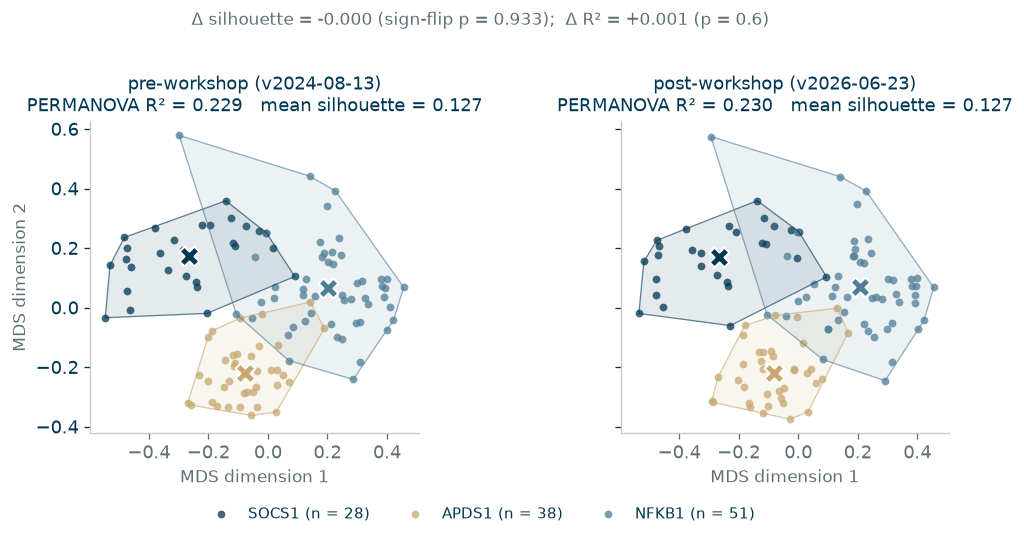

In [11]:
FIG_WIDTH = 9.6
C_INK, C_MUTED = "#003754", "#5f7078"
mpl.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": None,
    "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10.5,
    "font.family": "DejaVu Sans", "text.color": C_INK, "axes.titlesize": 11.5,
    "axes.labelsize": 10, "axes.labelcolor": C_MUTED, "axes.edgecolor": "#c4c9ce",
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": C_MUTED,
    "ytick.color": C_INK, "legend.frameon": False, "legend.fontsize": 9})

def save_panel(fig, name):
    for ext in ("png", "pdf", "svg"):
        fig.savefig(FPATH_FIGS / f"{name}.{ext}")
    w, h = fig.get_size_inches(); print(f"  saved {name}.png/.pdf/.svg  ({w:.2f} x {h:.2f} in)")

S_all = SIM[PRIMARY]
S_pre = sub_matrix(S_all, ["pre"] * N); S_post = sub_matrix(S_all, ["post"] * N)
X_pre = cmdscale(1 - S_pre); X_post = procrustes_align(X_pre, cmdscale(1 - S_post))
X_pre = X_pre - X_pre.mean(0)
r_all = res[(res.ic == PRIMARY[0]) & (res.measure == PRIMARY[1]) & (res.cohort == "all")].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 4.3), sharex=True, sharey=True)
for ax, X, title, R2, sil in ((axes[0], X_pre,  f"pre-workshop ({HPO_OLD_TAG})",  r_all.R2_pre,  r_all.sil_pre),
                              (axes[1], X_post, f"post-workshop ({HPO_NEW_TAG})", r_all.R2_post, r_all.sil_post)):
    for g in ORDER:
        m = labels == g; P = X[m]
        ax.scatter(P[:, 0], P[:, 1], s=22, color=COLOR[g], alpha=0.75, lw=0, label=f"{g} (n = {m.sum()})")
        if m.sum() >= 3:
            h = ConvexHull(P); poly = P[h.vertices]
            ax.fill(poly[:, 0], poly[:, 1], color=COLOR[g], alpha=0.10, lw=0)
            ax.plot(np.r_[poly[:, 0], poly[0, 0]], np.r_[poly[:, 1], poly[0, 1]], color=COLOR[g], lw=0.8, alpha=0.6)
        ax.scatter(*P.mean(0), marker="X", s=140, color=COLOR[g], edgecolor="white", lw=1.2, zorder=5)
    ax.set_title(f"{title}\nPERMANOVA R² = {R2:.3f}   mean silhouette = {sil:.3f}", fontsize=10.5)
    ax.set_xlabel("MDS dimension 1"); ax.set_aspect("equal", adjustable="box")
axes[0].set_ylabel("MDS dimension 2")
handles, labs = axes[1].get_legend_handles_labels()
fig.legend(handles, labs, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"Δ silhouette = {r_all.sil_delta:+.3f} (sign-flip p = {r_all.p_flip_sil:.3g});  "
             f"Δ R² = {r_all.R2_post - r_all.R2_pre:+.3f} (p = {r_all.p_flip_R2:.3g})", fontsize=10, color=C_MUTED, y=0.995)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
save_panel(fig, "figS4a_separation_mds")
plt.show()

  saved figS4b_separation_similarity.png/.pdf/.svg  (9.60 x 4.00 in)


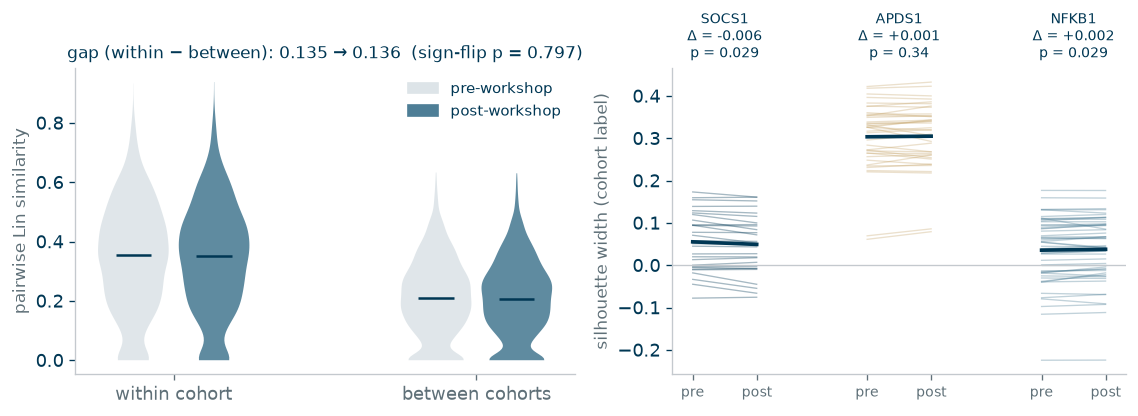

In [12]:
# Supplementary: within/between similarity per arm, and per-individual silhouette slopes
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 4.0), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axes[0]
same_coh = labels[iu[0]] == labels[iu[1]]
data = [S_pre[iu][same_coh], S_post[iu][same_coh], S_pre[iu][~same_coh], S_post[iu][~same_coh]]
pos  = [0.8, 1.2, 2.3, 2.7]
vp = ax.violinplot(data, positions=pos, widths=0.35, showmedians=True, showextrema=False)
for body, col in zip(vp["bodies"], ["#dde4e8", "#4e7e96", "#dde4e8", "#4e7e96"]):
    body.set_facecolor(col); body.set_edgecolor("none"); body.set_alpha(0.9)
vp["cmedians"].set_color(C_INK)
ax.set_xticks([1.0, 2.5]); ax.set_xticklabels(["within cohort", "between cohorts"])
ax.set_ylabel("pairwise Lin similarity")
ax.set_title(f"gap (within − between): {r_all.gap_pre:.3f} → {r_all.gap_post:.3f}  (sign-flip p = {r_all.p_flip_gap:.3g})", fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#dde4e8", label="pre-workshop"), Patch(color="#4e7e96", label="post-workshop")], loc="upper right")

ax = axes[1]
pp_ = pat[(pat.ic == PRIMARY[0]) & (pat.measure == PRIMARY[1])]
for k, g in enumerate(ORDER):
    sub = pp_[pp_.cohort == g]
    x0, x1 = k * 3 + 0.8, k * 3 + 1.9
    for _, r in sub.iterrows():
        ax.plot([x0, x1], [r.sil_pre, r.sil_post], color=COLOR[g], alpha=0.35, lw=0.8)
    ax.plot([x0, x1], [sub.sil_pre.mean(), sub.sil_post.mean()], color=C_INK, lw=2.2)
    rr = res[(res.ic == PRIMARY[0]) & (res.measure == PRIMARY[1]) & (res.cohort == g)].iloc[0]
    ax.text((x0 + x1) / 2, ax.get_ylim()[1] if False else 1.02, f"{g}\nΔ = {rr.sil_delta:+.3f}\np = {rr.p_holm:.2g}",
            ha="center", va="bottom", fontsize=8.5, color=C_INK, transform=ax.get_xaxis_transform())
ax.set_xticks([k * 3 + 0.8 for k in range(len(ORDER))] + [k * 3 + 1.9 for k in range(len(ORDER))])
ax.set_xticklabels(["pre"] * len(ORDER) + ["post"] * len(ORDER), fontsize=8.5)
ax.axhline(0, color="#c4c9ce", lw=0.8); ax.set_ylabel("silhouette width (cohort label)")
fig.tight_layout(rect=(0, 0, 1, 0.9))
save_panel(fig, "figS4b_separation_similarity")
plt.show()

## 7  separation tables

In [13]:
def fmt_p(p):
    if pd.isna(p): return ""
    return f"{p:.2g}" if p >= 1e-3 else f"{p:.1e}".replace("e-0", " × 10⁻").replace("e-", " × 10⁻")

t7 = res[(res.ic == PRIMARY[0]) & (res.measure == PRIMARY[1])].copy()
t7 = t7.assign(**{
    "silhouette (pre → post)": t7.apply(lambda r: f"{r.sil_pre:.3f} → {r.sil_post:.3f}", axis=1),
    "Δ silhouette": t7.sil_delta.map(lambda v: f"{v:+.3f}"),
    "improved/worse": t7.apply(lambda r: f"{r.sil_improved}/{r.sil_worse}", axis=1),
    "p (Wilcoxon, Holm)": t7.apply(lambda r: fmt_p(r.p_wilcoxon if r.cohort == "all" else r.p_holm), axis=1),
})[["cohort", "n", "silhouette (pre → post)", "Δ silhouette", "improved/worse", "p (Wilcoxon, Holm)"]]
t7.to_csv(FPATH_WORK / "tables/tableS8a_separation_cohorts.csv", index=False)

sens = res[res.cohort == "all"][["ic", "measure", "sil_pre", "sil_post", "p_flip_sil", "R2_pre", "R2_post", "p_flip_R2",
                                 "gap_pre", "gap_post", "p_flip_gap", "ari_pre", "ari_post", "p_flip_ari"]].round(4)
sens.to_csv(FPATH_WORK / "tables/tableS8b_separation_sensitivity.csv", index=False)
display(t7); sens

,cohort,n,silhouette (pre → post),Δ silhouette,improved/worse,"p (Wilcoxon, Holm)"
0,SOCS1,28,0.055 → 0.049,-0.006,10/18,0.029
1,APDS1,38,0.303 → 0.305,+0.001,21/17,0.34
2,NFKB1,51,0.036 → 0.038,+0.002,32/18,0.029
3,all,117,0.127 → 0.127,-0.000,63/53,0.37


,ic,measure,sil_pre,sil_post,p_flip_sil,R2_pre,R2_post,p_flip_R2,gap_pre,gap_post,p_flip_gap,ari_pre,ari_post,p_flip_ari
3,intrinsic,lin,0.1274,0.1272,0.9334,0.2291,0.2301,0.5999,0.1354,0.1358,0.7972,0.0015,-0.0010,0.6611
7,intrinsic,resnik,0.1104,0.1125,0.0896,0.2047,0.2101,0.0002,0.1204,0.1229,0.0202,-0.0010,-0.0010,1.0000
11,hpoa,lin,0.1308,0.1284,0.1266,0.2325,0.2312,0.5671,0.1354,0.1343,0.5393,-0.0179,0.0015,0.2002
15,hpoa,resnik,0.0703,0.0707,0.6225,0.1476,0.1530,0.0002,0.0824,0.0849,0.0016,-0.0070,0.0015,0.7397
